# AI-Based Zodiac Wardrobe Picker — MobileNetV2 Clothing Classifier

This notebook trains a **clothing-category image classifier** using TensorFlow/Keras and MobileNetV2 transfer learning.

**What this model does:** classifies an individual clothing photograph (for example, Shirt, T-shirt, Jeans, Jacket).

Dataset: [Fashion Product Images Dataset on Kaggle](https://www.kaggle.com/datasets/paramaggarwal/fashion-product-images-dataset). It contains product photos and `styles.csv` metadata with clothing labels such as `articleType`.

## 1. Choose a GPU runtime
**Runtime → Change runtime type → T4 GPU**

In [ ]:
import os, glob, zipfile, json, random
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

TensorFlow: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Put the dataset ZIP in Google Drive and extract it


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

ZIP_PATH = '/content/drive/MyDrive/datasets/fashion-product-images-dataset.zip'  # CHANGE THIS
EXTRACT_DIR = '/content/fashion_data'
os.makedirs(EXTRACT_DIR, exist_ok=True)

if not os.path.exists(ZIP_PATH):
    raise FileNotFoundError(f"ZIP not found: {ZIP_PATH}. Update ZIP_PATH to match your Drive file.")

with zipfile.ZipFile(ZIP_PATH, 'r') as zf:
    zf.extractall(EXTRACT_DIR)

print('Extraction complete.')
print('Top-level folders:', os.listdir(EXTRACT_DIR)[:20])

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Extraction complete.
Top-level folders: ['styles.csv', 'images', 'myntradataset']


## 3. Locate the CSV and image files

This cell searches the extracted folders, finds `styles.csv`, and indexes JPG/JPEG images. It supports the common `id` and `styleID` metadata column names.

In [ ]:
# Find styles.csv
csv_candidates = glob.glob(os.path.join(EXTRACT_DIR, '**', 'styles.csv'), recursive=True)
if not csv_candidates:
    raise FileNotFoundError('Could not find styles.csv inside the extracted ZIP.')
CSV_PATH = csv_candidates[0]
print('CSV:', CSV_PATH)

# Find all JPG/JPEG images recursively
image_paths = glob.glob(os.path.join(EXTRACT_DIR, '**', '*.jpg'), recursive=True)
image_paths += glob.glob(os.path.join(EXTRACT_DIR, '**', '*.jpeg'), recursive=True)
image_paths += glob.glob(os.path.join(EXTRACT_DIR, '**', '*.JPG'), recursive=True)

# Map image filename stem -> full path
image_lookup = {Path(p).stem: p for p in image_paths}
print('Images indexed:', len(image_lookup))

# Some releases have occasional malformed CSV rows; skip malformed rows.
df = pd.read_csv(CSV_PATH, on_bad_lines='skip', low_memory=False)
print('CSV columns:', df.columns.tolist())
print(df.head(3))

CSV: /content/fashion_data/styles.csv
Images indexed: 44441
CSV columns: ['id', 'gender', 'masterCategory', 'subCategory', 'articleType', 'baseColour', 'season', 'year', 'usage', 'productDisplayName']
      id gender masterCategory subCategory articleType baseColour  season  \
0  15970    Men        Apparel     Topwear      Shirts  Navy Blue    Fall   
1  39386    Men        Apparel  Bottomwear       Jeans       Blue  Summer   
2  59263  Women    Accessories     Watches     Watches     Silver  Winter   

     year   usage                  productDisplayName  
0  2011.0  Casual    Turtle Check Men Navy Blue Shirt  
1  2012.0  Casual  Peter England Men Party Blue Jeans  
2  2016.0  Casual            Titan Women Silver Watch  


## 4. Prepare labelled clothing categories

We use `articleType` as the target label. This first model is deliberately limited to a manageable selection of garment classes. Run this cell and inspect the printed category counts. If a class is missing in your dataset release, edit `REQUESTED_CLASSES` to use names shown in the output.

In [ ]:
label_col = 'articleType' if 'articleType' in df.columns else None
id_col = 'id' if 'id' in df.columns else ('styleID' if 'styleID' in df.columns else None)
if label_col is None or id_col is None:
    raise ValueError(f"Expected articleType and id/styleID columns. Found: {df.columns.tolist()}")

# Normalise IDs so values such as 12345.0 match image file 12345.jpg.
def norm_id(v):
    s = str(v).strip()
    if s.endswith('.0'):
        s = s[:-2]
    return s

df['image_id'] = df[id_col].map(norm_id)
df['label'] = df[label_col].astype(str).str.strip()
df['image_path'] = df['image_id'].map(image_lookup)
df = df[df['image_path'].notna()].copy()

print('Available article types (top 40):')
print(df['label'].value_counts().head(40).to_string())

REQUESTED_CLASSES = [
    'Shirts', 'Tshirts', 'Jeans', 'Trousers', 'Shorts',
    'Jackets', 'Dresses', 'Track Pants', 'Sweatshirts'
]
available = {x.casefold(): x for x in df['label'].unique()}
selected = [available[x.casefold()] for x in REQUESTED_CLASSES if x.casefold() in available]
if len(selected) < 2:
    raise ValueError('Fewer than 2 requested categories were found. Edit REQUESTED_CLASSES using the names printed above.')

work = df[df['label'].isin(selected)].copy()
counts = work['label'].value_counts()
# Drop very small classes so the stratified split and model training are meaningful.
MIN_IMAGES_PER_CLASS = 300
kept = counts[counts >= MIN_IMAGES_PER_CLASS].index.tolist()
work = work[work['label'].isin(kept)].copy()

# Optional cap for a quicker Colab demonstration. Set to None to use all available images.
MAX_PER_CLASS = 2500
if MAX_PER_CLASS is not None:
    work = (work.groupby('label', group_keys=False)
                 .apply(lambda x: x.sample(min(len(x), MAX_PER_CLASS), random_state=SEED))
                 .reset_index(drop=True))

print('Selected categories and image counts:')
print(work['label'].value_counts().to_string())
print('Total images used:', len(work))
if work['label'].nunique() < 2:
    raise ValueError('Not enough classes remain. Lower MIN_IMAGES_PER_CLASS or change REQUESTED_CLASSES.')

Available article types (top 40):
label
Tshirts                  7066
Shirts                   3215
Casual Shoes             2845
Watches                  2542
Sports Shoes             2036
Kurtas                   1844
Tops                     1762
Handbags                 1759
Heels                    1323
Sunglasses               1073
Wallets                   936
Flip Flops                914
Sandals                   897
Briefs                    849
Belts                     813
Backpacks                 724
Socks                     686
Formal Shoes              637
Perfume and Body Mist     613
Jeans                     608
Shorts                    547
Trousers                  530
Flats                     500
Bra                       477
Dresses                   464
Sarees                    427
Earrings                  416
Deodorant                 347
Nail Polish               329
Lipstick                  315
Track Pants               304
Clutches                  290


/tmp/ipykernel_1753/3762499297.py:41: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sample(min(len(x), MAX_PER_CLASS), random_state=SEED))


## 5. Split into training, validation and test sets

We use 70% training, 15% validation and 15% test data. The test set is held back until final evaluation.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()
work['label_id'] = encoder.fit_transform(work['label'])
class_names = encoder.classes_.tolist()
num_classes = len(class_names)

train_df, temp_df = train_test_split(
    work, test_size=0.30, random_state=SEED, stratify=work['label_id']
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, random_state=SEED, stratify=temp_df['label_id']
)

print('Classes:', class_names)
print(f'Train: {len(train_df)} | Validation: {len(val_df)} | Test: {len(test_df)}')

Classes: ['Dresses', 'Jeans', 'Shirts', 'Shorts', 'Track Pants', 'Trousers', 'Tshirts']
Train: 5217 | Validation: 1118 | Test: 1118


## 6. Build TensorFlow input pipelines

Images are decoded and resized to 224 × 224. The MobileNetV2 preprocessing operation will be included inside the model, so the exported model can accept regular RGB pixel values from 0 to 255.

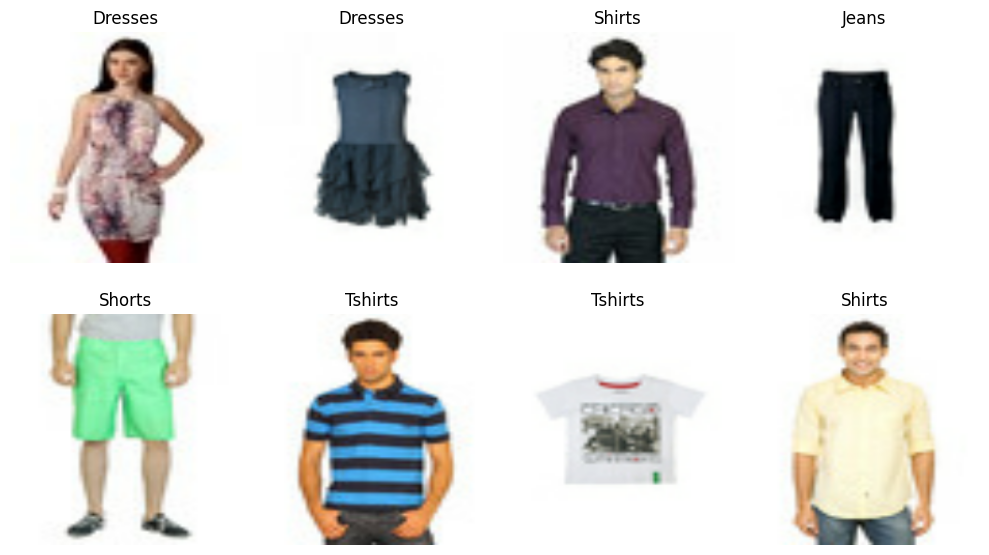

In [ ]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

def load_image(path, label):
    image_bytes = tf.io.read_file(path)
    image = tf.io.decode_image(image_bytes, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32)  # range remains approximately 0..255
    return image, tf.cast(label, tf.int32)

def make_dataset(frame, training=False):
    paths = frame['image_path'].astype(str).values
    labels = frame['label_id'].astype(np.int32).values
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        ds = ds.shuffle(min(len(frame), 5000), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)
    return ds

train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df)
test_ds = make_dataset(test_df)

# Display sample images
images, labels = next(iter(train_ds))
plt.figure(figsize=(10, 6))
for i in range(min(8, len(images))):
    plt.subplot(2, 4, i + 1)
    plt.imshow(tf.cast(images[i], tf.uint8).numpy())
    plt.title(class_names[int(labels[i])])
    plt.axis('off')
plt.tight_layout()
plt.show()

## 7. Build MobileNetV2 using transfer learning

MobileNetV2 is initialized with ImageNet weights. We freeze its pretrained feature extractor first and train a new classification head for our clothing classes. The rescaling layer maps pixels from `[0, 255]` to `[-1, 1]`, which is the expected MobileNetV2 input range.

In [ ]:
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2

base_model = MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights='imagenet'
)
base_model.trainable = False

inputs = layers.Input(shape=(224, 224, 3), name='image_rgb_0_255')
x = layers.RandomFlip('horizontal')(inputs)
x = layers.RandomRotation(0.04)(x)
x = layers.Rescaling(1.0 / 127.5, offset=-1, name='mobilenetv2_preprocessing')(x)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.25)(x)
outputs = layers.Dense(num_classes, activation='softmax', name='clothing_class')(x)

model = models.Model(inputs, outputs, name='clothing_mobilenetv2')
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "clothing_mobilenetv2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image_rgb_0_255 (InputLayer)    │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_preprocessing       │ (None, 224, 224, 3)    │             0 │
│ (Rescaling)                     │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ clothing_class (Dense)          │ (None, 7)              │         8,967 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,266,951 (8.65 MB)

 Trainable params: 8,967 (35.03 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 8. Train the classification head

Start with 8–12 epochs. Early stopping may stop earlier if validation loss stops improving. Training time depends on the available runtime/GPU and dataset size.

In [ ]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=2, min_lr=1e-6),
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=callbacks
)

Epoch 1/10
164/164 ━━━━━━━━━━━━━━━━━━━━ 23s 82ms/step - accuracy: 0.8041 - loss: 0.5786 - val_accuracy: 0.8918 - val_loss: 0.3063 - learning_rate: 0.0010
Epoch 2/10
164/164 ━━━━━━━━━━━━━━━━━━━━ 13s 66ms/step - accuracy: 0.9017 - loss: 0.2779 - val_accuracy: 0.9097 - val_loss: 0.2506 - learning_rate: 0.0010
Epoch 3/10
164/164 ━━━━━━━━━━━━━━━━━━━━ 12s 75ms/step - accuracy: 0.9226 - loss: 0.2209 - val_accuracy: 0.9213 - val_loss: 0.2198 - learning_rate: 0.0010
Epoch 4/10
164/164 ━━━━━━━━━━━━━━━━━━━━ 19s 68ms/step - accuracy: 0.9289 - loss: 0.2009 - val_accuracy: 0.9267 - val_loss: 0.2047 - learning_rate: 0.0010
Epoch 5/10
164/164 ━━━━━━━━━━━━━━━━━━━━ 11s 67ms/step - accuracy: 0.9383 - loss: 0.1799 - val_accuracy: 0.9249 - val_loss: 0.2021 - learning_rate: 0.0010
Epoch 6/10
164/164 ━━━━━━━━━━━━━━━━━━━━ 11s 66ms/step - accuracy: 0.9335 - loss: 0.1792 - val_accuracy: 0.9240 - val_loss: 0.1958 - learning_rate: 0.0010
Epoch 7/10
164/164 ━━━━━━━━━━━━━━━━━━━━ 12s 71ms/step - accuracy: 0.9427 - l

## 9. Plot training curves

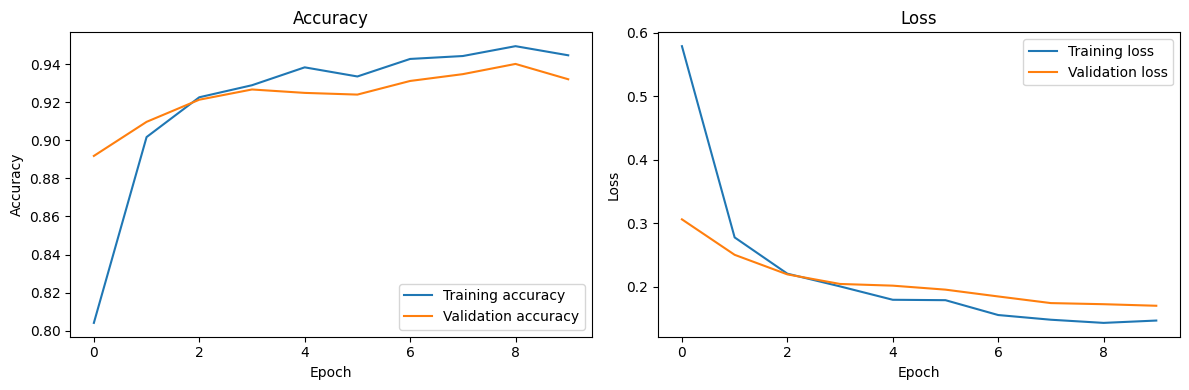

In [ ]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training accuracy')
plt.plot(history.history['val_accuracy'], label='Validation accuracy')
plt.xlabel('Epoch'); plt.ylabel('Accuracy'); plt.legend(); plt.title('Accuracy')
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training loss')
plt.plot(history.history['val_loss'], label='Validation loss')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.legend(); plt.title('Loss')
plt.tight_layout(); plt.show()

## 10. Optional fine-tuning

Only do this after the classifier head has trained. Unfreeze a small tail of the backbone and use a very low learning rate. If runtime is limited, you can skip this section.

In [ ]:
# Optional: fine-tune the last 30 MobileNetV2 layers.
base_model.trainable = True
for layer in base_model.layers[:-30]:
    layer.trainable = False
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

fine_tune_history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=3,
    callbacks=callbacks
)

Epoch 1/3
164/164 ━━━━━━━━━━━━━━━━━━━━ 22s 91ms/step - accuracy: 0.9565 - loss: 0.1219 - val_accuracy: 0.9526 - val_loss: 0.1464 - learning_rate: 1.0000e-05
Epoch 2/3
164/164 ━━━━━━━━━━━━━━━━━━━━ 13s 80ms/step - accuracy: 0.9634 - loss: 0.1079 - val_accuracy: 0.9445 - val_loss: 0.1440 - learning_rate: 1.0000e-05
Epoch 3/3
164/164 ━━━━━━━━━━━━━━━━━━━━ 14s 84ms/step - accuracy: 0.9670 - loss: 0.0934 - val_accuracy: 0.9481 - val_loss: 0.1417 - learning_rate: 1.0000e-05


## 11. Evaluate on the held-out test set

Report accuracy, precision, recall, F1-score and a confusion matrix. Weighted averages account for possible differences in class counts.

35/35 ━━━━━━━━━━━━━━━━━━━━ 4s 90ms/step
Test accuracy : 0.958
Precision     : 0.9593
Recall        : 0.958
F1-score      : 0.9582

Classification report:
              precision    recall  f1-score   support

     Dresses       0.94      0.96      0.95        70
       Jeans       0.96      0.90      0.93        91
      Shirts       0.96      0.99      0.98       375
      Shorts       0.97      0.93      0.95        82
 Track Pants       0.83      0.93      0.88        46
    Trousers       0.88      0.91      0.89        79
     Tshirts       0.99      0.96      0.97       375

    accuracy                           0.96      1118
   macro avg       0.93      0.94      0.94      1118
weighted avg       0.96      0.96      0.96      1118



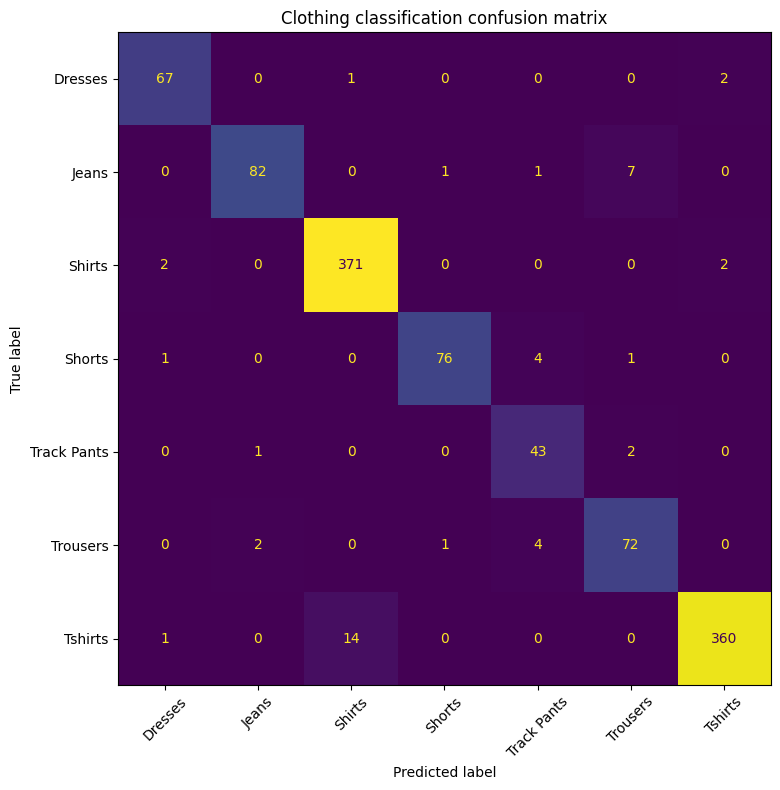

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

y_true = np.concatenate([y.numpy() for _, y in test_ds])
y_prob = model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

print('Test accuracy :', round(accuracy_score(y_true, y_pred), 4))
print('Precision     :', round(precision_score(y_true, y_pred, average='weighted', zero_division=0), 4))
print('Recall        :', round(recall_score(y_true, y_pred, average='weighted', zero_division=0), 4))
print('F1-score      :', round(f1_score(y_true, y_pred, average='weighted', zero_division=0), 4))
print('\nClassification report:')
print(classification_report(y_true, y_pred, target_names=class_names, zero_division=0))

cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
fig, ax = plt.subplots(figsize=(10, 8))
disp.plot(ax=ax, xticks_rotation=45, colorbar=False)
plt.title('Clothing classification confusion matrix')
plt.tight_layout(); plt.show()

## 12. Test one new clothing photograph

Upload one clear photo of an individual clothing item. The model returns the predicted category and confidence. Test on photos not used in the training dataset (for example, your own clothing photos) to understand real-world performance.

Saving Pgo7Il9Qbu4NGjVVs5FopJPyzrjDBwUv1442gmr5N7kkbCyx2s-4wTC8wzZdA14vP7NKzjPiGq9Lfb-AJh2uTQs7IgmgEp4J4p3IZIZv5w0cBellpLlrG4aZ0Xkgfh7VOEZ_PLU2eIcD3B972kXrCWZUcah7xmvCN8qoTClVcJcfSB726bssVZ9m-orx9Jg6.jpg to Pgo7Il9Qbu4NGjVVs5FopJPyzrjDBwUv1442gmr5N7kkbCyx2s-4wTC8wzZdA14vP7NKzjPiGq9Lfb-AJh2uTQs7IgmgEp4J4p3IZIZv5w0cBellpLlrG4aZ0Xkgfh7VOEZ_PLU2eIcD3B972kXrCWZUcah7xmvCN8qoTClVcJcfSB726bssVZ9m-orx9Jg6.jpg
Predicted category: Shirts
Confidence: 99.88%


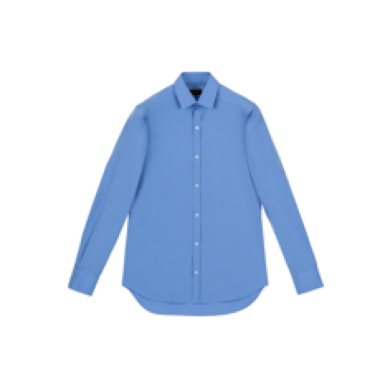

In [ ]:
from google.colab import files
from PIL import Image

uploaded = files.upload()  # choose one JPG/PNG clothing photograph
for filename in uploaded.keys():
    img = Image.open(filename).convert('RGB').resize(IMG_SIZE)
    arr = np.array(img, dtype=np.float32)[None, ...]
    probs = model.predict(arr, verbose=0)[0]
    best = int(np.argmax(probs))
    print('Predicted category:', class_names[best])
    print('Confidence:', f'{probs[best] * 100:.2f}%')
    plt.imshow(img); plt.axis('off'); plt.show()

## 13. Export the trained model and class labels

The correct Keras export is a `.keras` file. Save the class order separately as JSON so the backend maps model output indices to the correct clothing names.

In [ ]:
EXPORT_DIR = '/content/model_export'
os.makedirs(EXPORT_DIR, exist_ok=True)
MODEL_PATH = os.path.join(EXPORT_DIR, 'clothing_mobilenetv2.keras')
LABELS_PATH = os.path.join(EXPORT_DIR, 'labels.json')

model.save(MODEL_PATH)
with open(LABELS_PATH, 'w') as f:
    json.dump({str(i): name for i, name in enumerate(class_names)}, f, indent=2)

print('Saved:', MODEL_PATH)
print('Saved:', LABELS_PATH)

# Bundle both files for download
BUNDLE_PATH = '/content/clothing_model_bundle.zip'
with zipfile.ZipFile(BUNDLE_PATH, 'w', zipfile.ZIP_DEFLATED) as z:
    z.write(MODEL_PATH, arcname='clothing_mobilenetv2.keras')
    z.write(LABELS_PATH, arcname='labels.json')

files.download(BUNDLE_PATH)

Saved: /content/model_export/clothing_mobilenetv2.keras
Saved: /content/model_export/labels.json


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 14. Load the model in your backend later

Example FastAPI/Python loading code:

```python
import json
import tensorflow as tf

model = tf.keras.models.load_model("clothing_mobilenetv2.keras")
with open("labels.json", "r") as f:
    label_map = json.load(f)

# For each uploaded image, resize to 224x224 RGB and create a float32 array
# with shape (1, 224, 224, 3) and pixel values 0..255.
# The model includes MobileNetV2 preprocessing internally.
# probabilities = model.predict(image_array)
# predicted_index = int(probabilities[0].argmax())
# predicted_label = label_map[str(predicted_index)]
```

**Important limitations:** this is an image classifier, not an object detector or segmentation model. It works best when each uploaded image shows one main garment clearly. If you later want to identify multiple separate garments in a single wardrobe photo, add a detector (such as a YOLO clothing detector) or crop garments before classification. Dominant colour extraction can remain a separate OpenCV step.